Usage example
=============

In this example notebook we learn the basics of how to use `stissplice` to splice STIS *echèlle* spectra measured with *HST*. We start by importing the necessary packages.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from stissplice import splicer

# Uncomment the next line if you have a MacBook with retina screen
# %config InlineBackend.figure_format = 'retina'
pylab.rcParams['figure.figsize'] = 9.0,6.5
pylab.rcParams['font.size'] = 18

STIS *echèlle* spectra are composed of many orders that overlap in their edges. Here's how it looks when we read an `x1d` file:

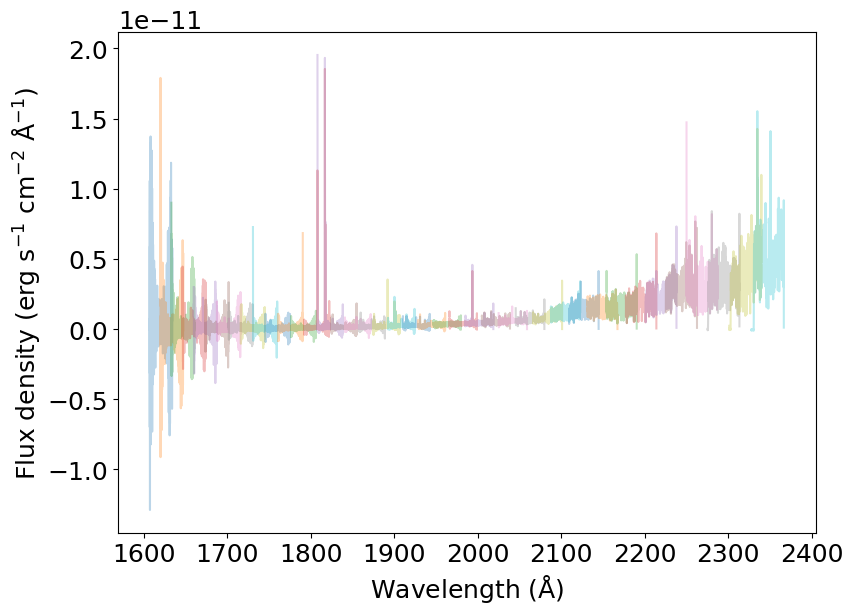

In [2]:
dataset = 'oblh01040'
prefix = '../../data/'

spectrum = splicer.read_spectrum(dataset, prefix)

for s in spectrum:
    plt.plot(s['wavelength'], s['flux'], alpha=0.3)
_ = plt.xlabel(r'Wavelength (${\rm \AA}$)')
_ = plt.ylabel(r'Flux density (erg s$^{-1}$ cm$^{-2}$ ${\rm \AA}^{-1}$)')

If we zoom in, we can see the order overlap in more detail.

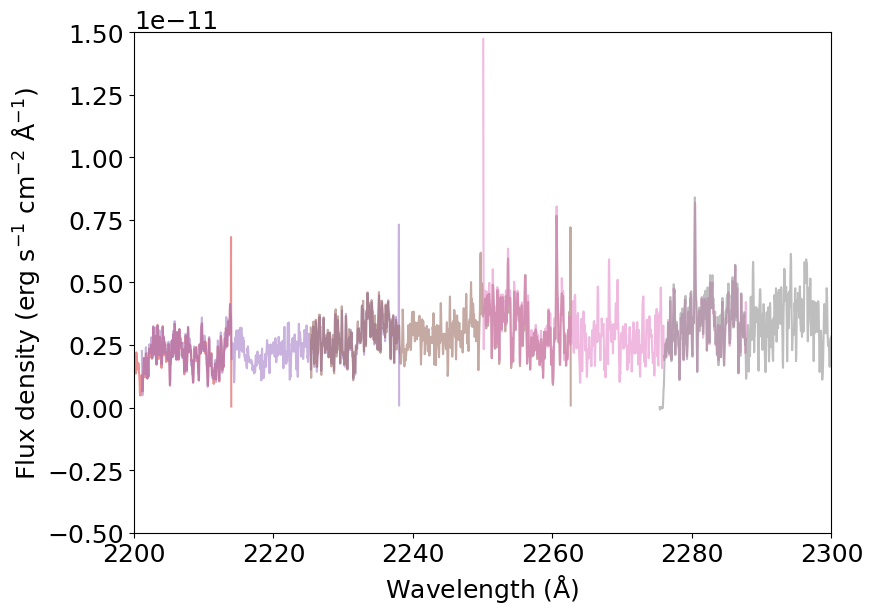

In [3]:
for s in spectrum:
    plt.plot(s['wavelength'], s['flux'], alpha=0.5)
_ = plt.xlabel(r'Wavelength (${\rm \AA}$)')
_ = plt.ylabel(r'Flux density (erg s$^{-1}$ cm$^{-2}$ ${\rm \AA}^{-1}$)')
_ = plt.xlim(2200, 2300)
_ = plt.ylim(-.5E-11, 1.5E-11)

The objective of the `stissplice` package is precisely to deal with the order overlap and co-add them to produce a one-dimensional spectrum. We do that using the `splice_pipeline()` function.

In [4]:
spliced_spectrum = splicer.splice_pipeline(dataset, prefix, weight='sensitivity')

And now we plot it in black and compare it to the original spectra in colors.

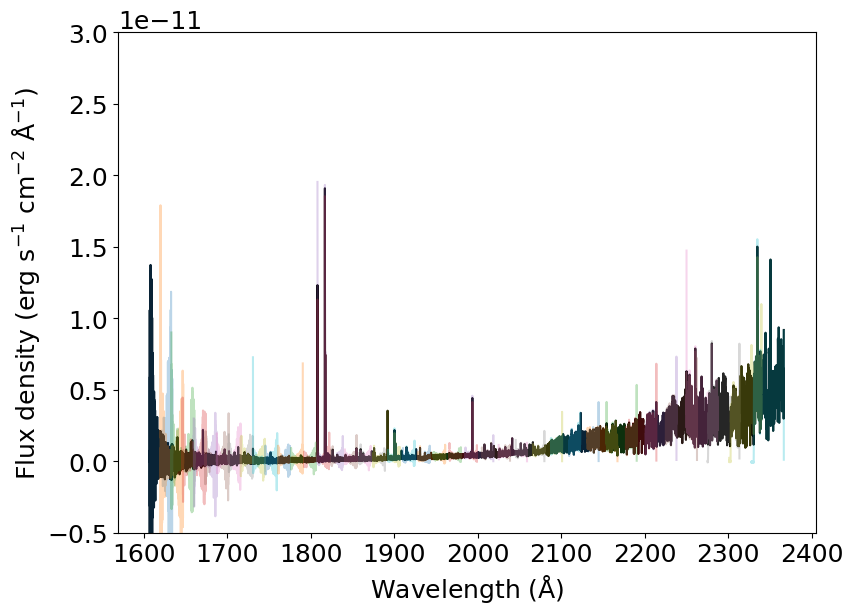

In [5]:
plt.plot(spliced_spectrum['WAVELENGTH'], spliced_spectrum['FLUX'], color='k')

for s in spectrum:
    plt.plot(s['wavelength'], s['flux'], alpha=0.3)
_ = plt.xlabel(r'Wavelength (${\rm \AA}$)')
_ = plt.ylabel(r'Flux density (erg s$^{-1}$ cm$^{-2}$ ${\rm \AA}^{-1}$)')
_ = plt.ylim(-.5E-11, 3E-11)

And here's how the zoomed-in part looks like:

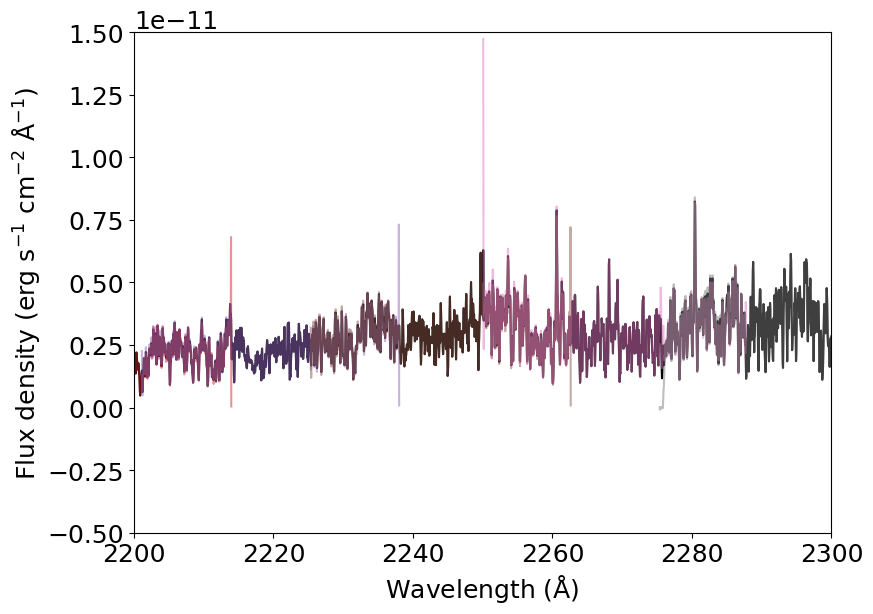

In [6]:
plt.plot(spliced_spectrum['WAVELENGTH'], spliced_spectrum['FLUX'], color='k')

for s in spectrum:
    plt.plot(s['wavelength'], s['flux'], alpha=0.5)
_ = plt.xlabel(r'Wavelength (${\rm \AA}$)')
_ = plt.ylabel(r'Flux density (erg s$^{-1}$ cm$^{-2}$ ${\rm \AA}^{-1}$)')
_ = plt.xlim(2200, 2300)
_ = plt.ylim(-.5E-11, 1.5E-11)